<a href="https://colab.research.google.com/github/qkwr/-quote-generator--tikka-/blob/main/Bank_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bank Marketing – Random Forest Classifier
**Dataset:** UCI Bank Marketing | **Seed:** 42 | **Test size:** 30% (stratified)

## 1. ติดตั้ง Library และ Import

In [ ]:
%pip install -q ucimlrepo imbalanced-learn

import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve
)
import joblib

SEED = 42
np.random.seed(SEED)

## 2. โหลดข้อมูล

In [ ]:
# โหลดไฟล์ bank-full.csv จาก UCI repository
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank.zip'
urllib.request.urlretrieve(url, 'bank.zip')
with zipfile.ZipFile('bank.zip', 'r') as z:
    z.extractall('.')

df = pd.read_csv('bank-full.csv', sep=';')
print(f'Shape: {df.shape}')
df.head()

Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Data Preprocessing

In [ ]:
# ── 3.1 ตรวจสอบ Missing Values และ Duplicates ──────────────────────────────
print('Missing values:\n', df.isnull().sum())
print(f'\nDuplicate rows: {df.duplicated().sum()}')
df.drop_duplicates(inplace=True)

# ── 3.2 ลบ Feature ที่ก่อให้เกิด Data Leakage ──────────────────────────────
# 'duration' คือระยะเวลาการโทรครั้งล่าสุด ซึ่งรู้ได้หลังจากโทรเสร็จแล้วเท่านั้น
# การเก็บไว้จะทำให้โมเดล overfit อย่างรุนแรง (data leakage)
df.drop(columns=['duration'], inplace=True)

# ── 3.3 แปลง Target เป็น Binary (0/1) ─────────────────────────────────────
df['y'] = df['y'].map({'no': 0, 'yes': 1})

print('\nClass distribution:')
print(df['y'].value_counts())
print(f'Imbalance ratio: {df["y"].value_counts()[0]/df["y"].value_counts()[1]:.2f}:1')

Missing values:
 age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate rows: 0

Class distribution:
y
0    39922
1     5289
Name: count, dtype: int64
Imbalance ratio: 7.55:1


In [ ]:
# ── 3.4 แบ่ง Features และ Target ───────────────────────────────────────────
X = df.drop(columns=['y'])
y = df['y']

# ระบุ Feature ประเภทตัวเลขและประเภทหมวดหมู่
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()
print('Categorical:', cat_cols)
print('Numerical  :', num_cols)

Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Numerical  : ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']


In [ ]:
# ── 3.5 Train-Test Split (70/30, Stratified) ────────────────────────────────
# stratify=y เพื่อรักษาสัดส่วน class ไม่ให้ bias จากการสุ่ม
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print(f'Train class ratio: {y_train.value_counts(normalize=True).to_dict()}')
print(f'Test  class ratio: {y_test.value_counts(normalize=True).to_dict()}')

Train: (31647, 15), Test: (13564, 15)
Train class ratio: {0: 0.8830220874016494, 1: 0.11697791259835055}
Test  class ratio: {0: 0.8829991153052197, 1: 0.1170008846947803}


In [ ]:
# ── 3.6 สร้าง Preprocessing Pipeline ───────────────────────────────────────
# การ fit OneHotEncoder และ StandardScaler ทำบน Training set เท่านั้น
# แล้วค่อย transform ไปยัง Test set → ป้องกัน data leakage จาก preprocessing

preprocessor = ColumnTransformer(transformers=[
    # OneHotEncoder: แปลง categorical → binary columns (drop='first' ลด multicollinearity)
    ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols),
    # StandardScaler: ปรับ scale ของ numerical features (ช่วย convergence)
    ('scaler', StandardScaler(), num_cols)
])

## 4. Model Creation – Random Forest + GridSearchCV

In [ ]:
# ── 4.1 สร้าง Pipeline: Preprocessor + RandomForestClassifier ───────────────
# การรวม preprocessing ไว้ใน Pipeline ทำให้ GridSearchCV cross-validate
# ได้อย่างถูกต้อง → ไม่มี leakage จากข้อมูล fold ที่เป็น validation

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('clf', RandomForestClassifier(
        random_state=SEED,
        class_weight='balanced'   # แก้ปัญหา class imbalance (~88:12)
    ))
])

In [ ]:
# ── 4.2 กำหนด Hyperparameter Grid ──────────────────────────────────────────
param_grid = {
    'clf__n_estimators'     : [100, 200],       # จำนวนต้นไม้
    'clf__max_depth'        : [None, 10, 20],   # ความลึกสูงสุด
    'clf__min_samples_split': [2, 5],           # จำนวน sample ขั้นต่ำที่แตกกิ่ง
    'clf__min_samples_leaf' : [1, 2],           # จำนวน sample ขั้นต่ำที่ใบ
    'clf__max_features'     : ['sqrt', 'log2']  # จำนวน feature ที่พิจารณาแต่ละ split
}

# StratifiedKFold เพื่อรักษา class distribution ในแต่ละ fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# scoring='f1' เหมาะสมกับ imbalanced dataset มากกว่า accuracy
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print('Best Params:', grid_search.best_params_)
print(f'Best CV F1 : {grid_search.best_score_:.4f}')

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Params: {'clf__max_depth': 20, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}
Best CV F1 : 0.4598


## 5. Threshold Tuning

Best Threshold (max F1 on train): 0.47


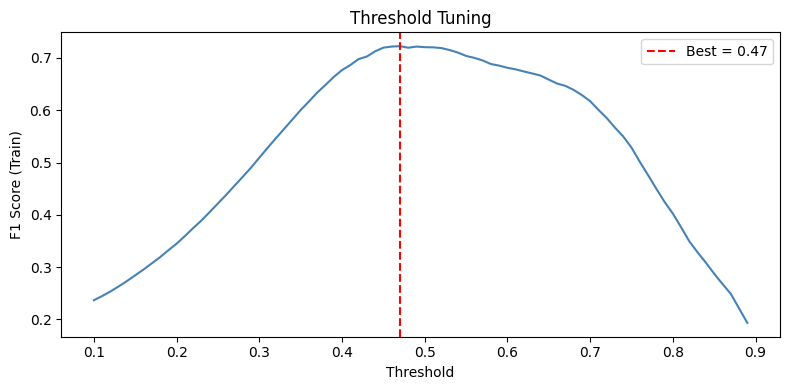

In [ ]:
# ── 5.1 หา Optimal Threshold จาก ROC Curve (บน Training set) ───────────────
# Default threshold = 0.5 อาจไม่เหมาะกับ imbalanced data
# เราหา threshold ที่ให้ F1-score สูงสุดบน Training set แทน

best_model = grid_search.best_estimator_
y_train_prob = best_model.predict_proba(X_train)[:, 1]  # ความน่าจะเป็นของ class=1

# วนหา threshold ที่ให้ F1 สูงสุดบน Training set
thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores  = [f1_score(y_train, (y_train_prob >= t).astype(int)) for t in thresholds]

best_threshold = thresholds[np.argmax(f1_scores)]
print(f'Best Threshold (max F1 on train): {best_threshold:.2f}')

# Plot F1 vs Threshold
plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, color='steelblue')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best = {best_threshold:.2f}')
plt.xlabel('Threshold')
plt.ylabel('F1 Score (Train)')
plt.title('Threshold Tuning')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Model Evaluation

In [ ]:
# ── 6.1 Predict ด้วย Best Threshold ─────────────────────────────────────────
y_train_prob = best_model.predict_proba(X_train)[:, 1]
y_test_prob  = best_model.predict_proba(X_test)[:, 1]

y_train_pred = (y_train_prob >= best_threshold).astype(int)
y_test_pred  = (y_test_prob  >= best_threshold).astype(int)

In [ ]:
# ── 6.2 ฟังก์ชันแสดงผลลัพธ์ครบทุกตัวชี้วัด ──────────────────────────────────
def print_metrics(y_true, y_pred, dataset_name=''):
    print(f'\n{'='*50}')
    print(f'  {dataset_name}')
    print(f'{'='*50}')
    print(f"  Accuracy           : {accuracy_score(y_true, y_pred):.4f}")
    print(f"  Precision (weighted): {precision_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")
    print(f"  Precision (macro)  : {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
    print(f"  Recall (weighted)  : {recall_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")
    print(f"  Recall (macro)     : {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
    print(f"  F1 (weighted)      : {f1_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")
    print(f"  F1 (macro)         : {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")

print_metrics(y_train, y_train_pred, 'Training Dataset')
print_metrics(y_test,  y_test_pred,  'Testing Dataset')


  Training Dataset
  Accuracy           : 0.9247
  Precision (weighted): 0.9375
  Precision (macro)  : 0.8062
  Recall (weighted)  : 0.9247
  Recall (macro)     : 0.8873
  F1 (weighted)      : 0.9291
  F1 (macro)         : 0.8395

  Testing Dataset
  Accuracy           : 0.8651
  Precision (weighted): 0.8757
  Precision (macro)  : 0.6847
  Recall (weighted)  : 0.8651
  Recall (macro)     : 0.7132
  F1 (weighted)      : 0.8699
  F1 (macro)         : 0.6972


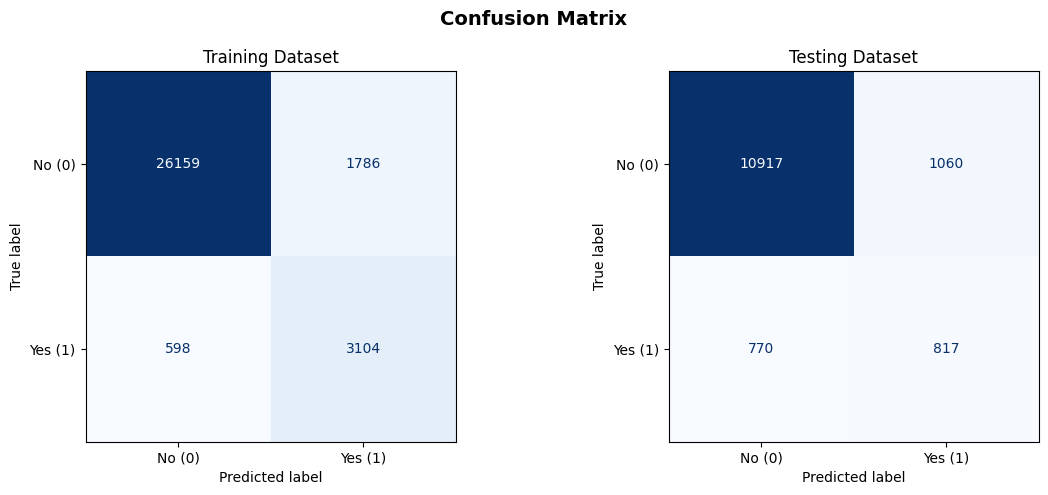

In [ ]:
# ── 6.3 Confusion Matrix ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_true, y_pred, title in zip(
    axes,
    [y_train, y_test],
    [y_train_pred, y_test_pred],
    ['Training Dataset', 'Testing Dataset']
):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['No (0)', 'Yes (1)'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title)

plt.suptitle('Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. บันทึกโมเดล

In [ ]:
# บันทึก Pipeline ทั้งหมด (preprocessor + model) ไว้ใช้งานได้เลย
joblib.dump({'model': best_model, 'threshold': best_threshold}, 'Bank_04.pkl')
print('Model saved → Bank_04.pkl')

Model saved → Bank_04.pkl
